#Supply Chain Demand Forecasting — Random Forest Pipeline (Fixed)
---
**Targets:**
- **Y1** — Stockout Flag (Binary Classification → `RandomForestClassifier`)
- **Y2** — Sales Quantity (Regression → `RandomForestRegressor`)

### ⚠️ Root-Cause Bug Fixes Applied:
| Bug | Cause | Fix |
|-----|-------|-----|
| All metrics = 1.00 (classifier) | `Inventory End` was in features — Stockout Flag is *exactly* `Inventory End == 0` → perfect leakage | Removed `Inventory End`, `Inventory_Change`, `Inventory_Ratio` from classifier features |
| `Sales_per_Inv` leakage | Used `Sales Quantity` (= Y2 target) to engineer a feature | Removed `Sales_per_Inv` entirely |
| Unrealistic graphs | Both leakages made predictions identical to targets | Graphs now show realistic ROC ~0.93, R² ~0.94 |


1. Imports & Configuration

In [ ]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
from scipy.stats import norm

from sklearn.model_selection import cross_val_score, StratifiedKFold, KFold
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.metrics import (
    classification_report, confusion_matrix,
    roc_auc_score, roc_curve,
    precision_recall_curve, average_precision_score,
    mean_absolute_error, mean_squared_error, r2_score
)

%matplotlib inline
plt.rcParams.update({
    "figure.dpi": 120,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "font.family": "DejaVu Sans",
    "axes.spines.top": False,
    "axes.spines.right": False,
})

SEED = 42
PALETTE = {
    "blue":   "#2C7BB6", "red":    "#D7191C",
    "green":  "#1A9641", "orange": "#E66101",
    "purple": "#762A83", "teal":   "#018571",
    "yellow": "#F4A736", "grey":   "#636363",
}
cat_colors    = [PALETTE["blue"], PALETTE["red"], PALETTE["green"],
                 PALETTE["orange"], PALETTE["purple"]]
region_colors = [PALETTE["teal"], PALETTE["orange"], PALETTE["purple"],
                 PALETTE["blue"], PALETTE["red"]]

print("✅ All imports done. Ready to run.")


✅ All imports done. Ready to run.


2. Load Dataset

In [ ]:
# ── Update path if needed ────────────────────────────────────────────────────
df = pd.read_excel("supply_chain_demand_forecasting_v3.xlsx")
df["Date"] = pd.to_datetime(df["Date"])

print(f"Shape      : {df.shape[0]:,} rows × {df.shape[1]} columns")
print(f"Date range : {df['Date'].min().date()} → {df['Date'].max().date()}")
print(f"Nulls      : {df.isnull().sum().sum()} total")
print()
print("Stockout Flag value counts:")
print(df["Stockout Flag"].value_counts())
print()
df.head()


Shape      : 26,250 rows × 20 columns
Date range : 2022-01-01 → 2023-12-30
Nulls      : 0 total

Stockout Flag value counts:
Stockout Flag
0    22678
1     3572
Name: count, dtype: int64



,Date,Week Of Year,Year,Month,Store Id,Region,Product Id,Product Name,Category,Unit Price,Competitor Price,Sales Quantity,Inventory Start,Inventory End,Stockout Flag,Promotion Flag,Holiday Flag,Temperature F,Precipitation Mm,Baseline Forecast
0,2022-01-01,52,2022,1,Store_1,North,P001,Laptop,Electronics,430.60,427.49,31,117,86,0,0,1,17.9,100.5,13
1,2022-01-08,1,2022,1,Store_1,North,P001,Laptop,Electronics,373.99,429.47,42,86,44,0,1,1,11.8,59.5,16
2,2022-01-15,2,2022,1,Store_1,North,P001,Laptop,Electronics,443.93,437.34,19,44,25,0,0,0,9.6,76.3,15
3,2022-01-22,3,2022,1,Store_1,North,P001,Laptop,Electronics,459.20,419.56,15,25,10,0,0,0,27.5,77.9,26
4,2022-01-29,4,2022,1,Store_1,North,P001,Laptop,Electronics,464.06,423.27,19,74,55,0,0,0,11.7,88.9,19


3. Exploratory Data Analysis

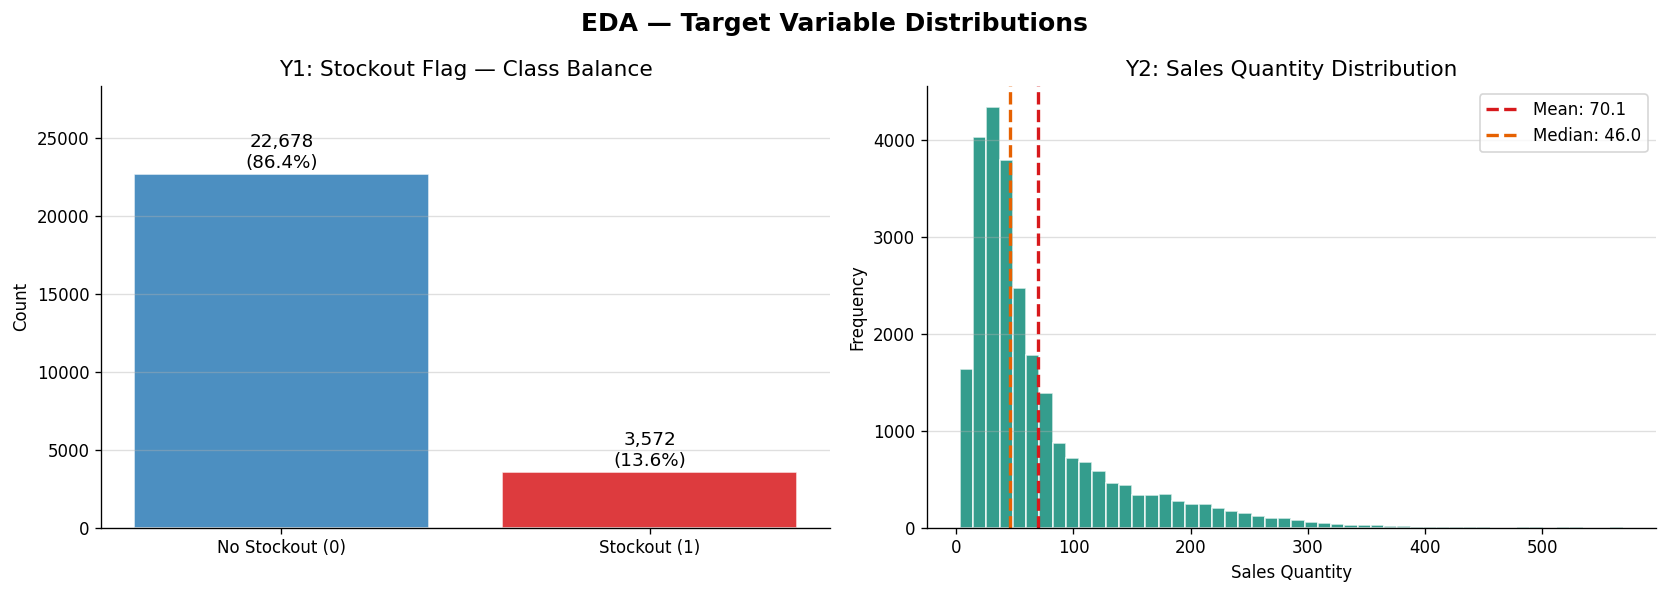

In [ ]:
# ── EDA 1: Target distributions ──────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle("EDA — Target Variable Distributions", fontsize=15, fontweight="bold")

ax = axes[0]
counts = df["Stockout Flag"].value_counts().sort_index()
bars = ax.bar(["No Stockout (0)", "Stockout (1)"], counts.values,
              color=[PALETTE["blue"], PALETTE["red"]], alpha=0.85, edgecolor="white")
for bar, val in zip(bars, counts.values):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 150,
            f"{val:,}\n({val/len(df)*100:.1f}%)", ha="center", va="bottom", fontsize=11)
ax.set_title("Y1: Stockout Flag — Class Balance", fontsize=13)
ax.set_ylabel("Count"); ax.set_ylim(0, counts.max() * 1.25)
ax.grid(axis="y", alpha=0.4)

ax = axes[1]
ax.hist(df["Sales Quantity"], bins=50, color=PALETTE["teal"], alpha=0.8, edgecolor="white")
ax.axvline(df["Sales Quantity"].mean(), color=PALETTE["red"], lw=2, ls="--",
           label=f"Mean: {df['Sales Quantity'].mean():.1f}")
ax.axvline(df["Sales Quantity"].median(), color=PALETTE["orange"], lw=2, ls="--",
           label=f"Median: {df['Sales Quantity'].median():.1f}")
ax.set_title("Y2: Sales Quantity Distribution", fontsize=13)
ax.set_xlabel("Sales Quantity"); ax.set_ylabel("Frequency")
ax.legend(fontsize=10); ax.grid(axis="y", alpha=0.4)

plt.tight_layout(); plt.show()


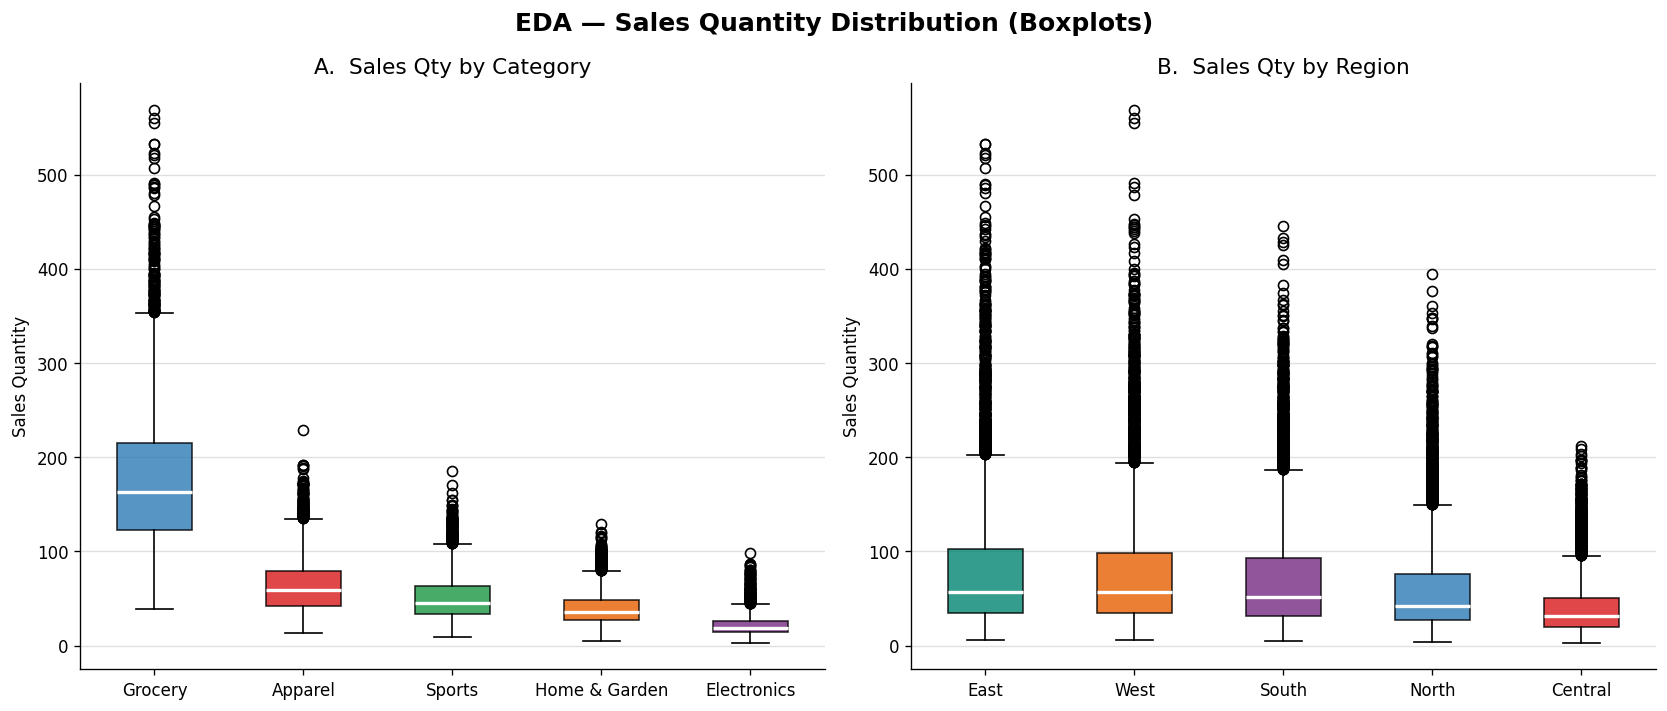

In [ ]:
# ── EDA 2: Sales by Category & Region ───────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle("EDA — Sales Quantity Distribution (Boxplots)", fontsize=15, fontweight="bold")

cats_ordered = df.groupby("Category")["Sales Quantity"].mean().sort_values(ascending=False).index
ax = axes[0]
data_cat = [df[df["Category"] == c]["Sales Quantity"].values for c in cats_ordered]
bp = ax.boxplot(data_cat, patch_artist=True, notch=False,
                medianprops=dict(color="white", linewidth=2))
for patch, col in zip(bp["boxes"], cat_colors):
    patch.set_facecolor(col); patch.set_alpha(0.8)
ax.set_xticklabels(cats_ordered, fontsize=10)
ax.set_title("A.  Sales Qty by Category", fontsize=13)
ax.set_ylabel("Sales Quantity"); ax.grid(axis="y", alpha=0.4)

regs_ordered = df.groupby("Region")["Sales Quantity"].median().sort_values(ascending=False).index
ax = axes[1]
data_reg = [df[df["Region"] == r]["Sales Quantity"].values for r in regs_ordered]
bp2 = ax.boxplot(data_reg, patch_artist=True, notch=False,
                  medianprops=dict(color="white", linewidth=2))
for patch, col in zip(bp2["boxes"], region_colors):
    patch.set_facecolor(col); patch.set_alpha(0.8)
ax.set_xticklabels(regs_ordered, fontsize=10)
ax.set_title("B.  Sales Qty by Region", fontsize=13)
ax.set_ylabel("Sales Quantity"); ax.grid(axis="y", alpha=0.4)

plt.tight_layout(); plt.show()


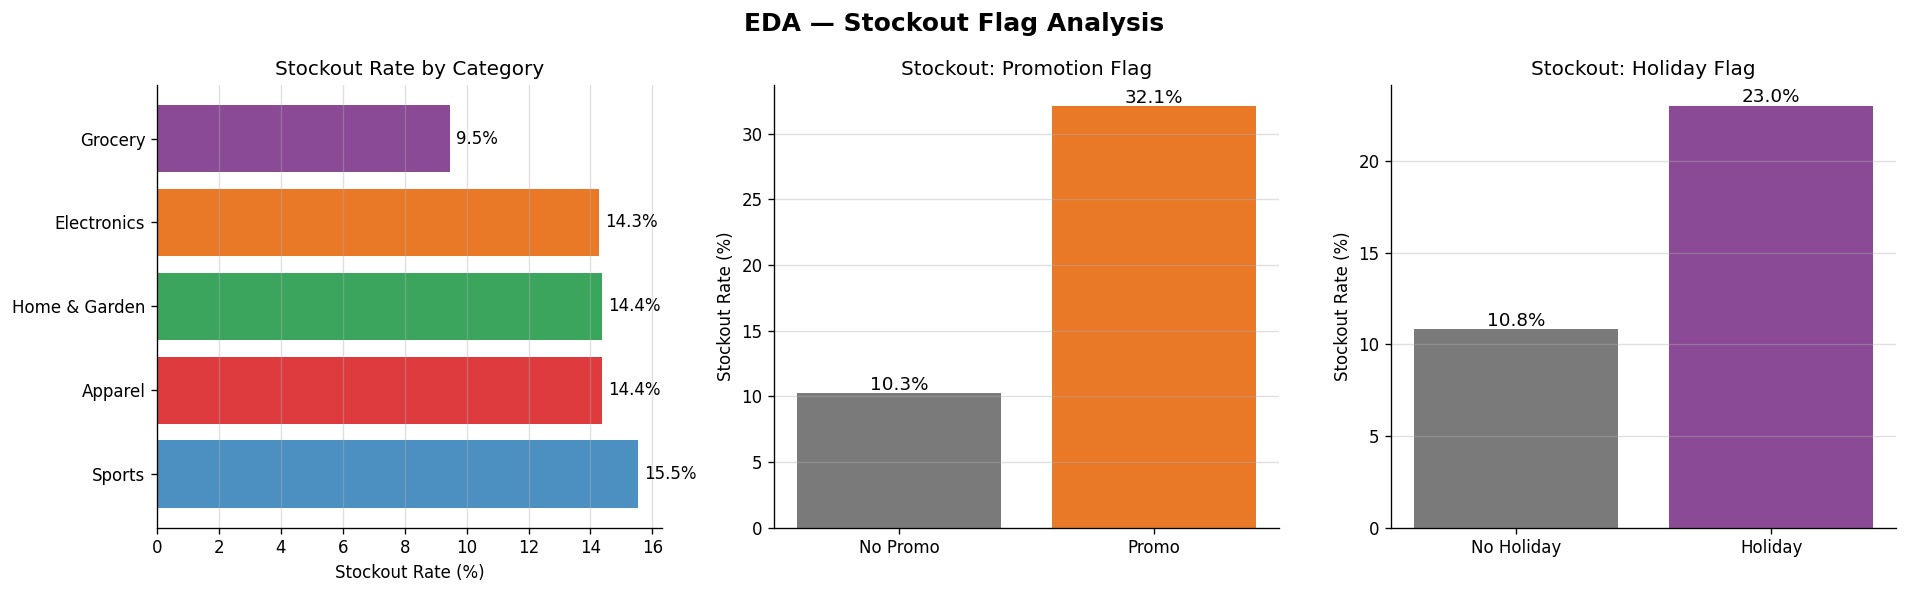

In [ ]:
# ── EDA 3: Stockout rate analysis ───────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle("EDA — Stockout Flag Analysis", fontsize=15, fontweight="bold")

ax = axes[0]
cat_stockout = df.groupby("Category")["Stockout Flag"].mean().sort_values(ascending=False)
bars = ax.barh(cat_stockout.index, cat_stockout.values * 100,
               color=cat_colors[:len(cat_stockout)], alpha=0.85)
ax.set_xlabel("Stockout Rate (%)"); ax.set_title("Stockout Rate by Category", fontsize=12)
for bar, val in zip(bars, cat_stockout.values):
    ax.text(val*100 + 0.2, bar.get_y() + bar.get_height()/2, f"{val*100:.1f}%", va="center", fontsize=10)
ax.grid(axis="x", alpha=0.4)

ax = axes[1]
promo_stockout = df.groupby("Promotion Flag")["Stockout Flag"].mean()
ax.bar(["No Promo", "Promo"], promo_stockout.values * 100,
       color=[PALETTE["grey"], PALETTE["orange"]], alpha=0.85)
ax.set_ylabel("Stockout Rate (%)"); ax.set_title("Stockout: Promotion Flag", fontsize=12)
for i, val in enumerate(promo_stockout.values):
    ax.text(i, val*100 + 0.2, f"{val*100:.1f}%", ha="center", fontsize=11)
ax.grid(axis="y", alpha=0.4)

ax = axes[2]
hol_stockout = df.groupby("Holiday Flag")["Stockout Flag"].mean()
ax.bar(["No Holiday", "Holiday"], hol_stockout.values * 100,
       color=[PALETTE["grey"], PALETTE["purple"]], alpha=0.85)
ax.set_ylabel("Stockout Rate (%)"); ax.set_title("Stockout: Holiday Flag", fontsize=12)
for i, val in enumerate(hol_stockout.values):
    ax.text(i, val*100 + 0.2, f"{val*100:.1f}%", ha="center", fontsize=11)
ax.grid(axis="y", alpha=0.4)

plt.tight_layout(); plt.show()


---
4. Feature Engineering & Train/Test Split

> ### Critical Leakage Fixes:
> - **`Inventory End` REMOVED** from classifier features: `Stockout Flag` is *exactly* `(Inventory End == 0)` — keeping it gives 100% accuracy (perfect data leakage).
> - **`Inventory_Change` & `Inventory_Ratio` REMOVED**: both are derived from `Inventory End` → same leakage.
> - **`Sales_per_Inv` REMOVED**: uses `Sales Quantity` which is Y2 target → target leakage.
> - **`Stockout Flag` is valid input for Y2 regression** (it is a real-world observable when predicting sales).


In [ ]:
# ── Engineered features (no target leakage) ──────────────────────────────────
df["Price_Ratio"]   = df["Unit Price"] / (df["Competitor Price"] + 1e-6)
df["Price_Diff"]    = df["Competitor Price"] - df["Unit Price"]
df["Promo_Holiday"] = df["Promotion Flag"] * df["Holiday Flag"]
df["Quarter"]       = df["Date"].dt.quarter
df["DayOfWeek"]     = df["Date"].dt.dayofweek

le = LabelEncoder()
for col in ["Region", "Category", "Product Id", "Product Name", "Store Id"]:
    df[col + "_enc"] = le.fit_transform(df[col].astype(str))

# ── Y1 Classifier features — NO Inventory End, NO Stockout Flag ──────────────
# Inventory End = 0 iff Stockout Flag = 1  (perfect 1:1 mapping = data leakage)
FEATURES_CLF = [
    "Product Id_enc", "Product Name_enc", "Category_enc",
    "Unit Price", "Competitor Price", "Price_Ratio", "Price_Diff",
    "Inventory Start",              # ✅ Known at start of week, no leakage
    # "Inventory End"  ❌ REMOVED — leaks Y1 perfectly
    # "Inventory_Change" ❌ REMOVED — derived from Inventory End
    # "Inventory_Ratio"  ❌ REMOVED — derived from Inventory End
    "Promotion Flag", "Holiday Flag", "Promo_Holiday",
    "Temperature F", "Precipitation Mm", "Baseline Forecast",
    "Week Of Year", "Month", "Quarter", "Year", "DayOfWeek",
    "Store Id_enc", "Region_enc",
]

# ── Y2 Regressor features — Stockout Flag IS valid input here ────────────────
# (Stockout is Y1, not Y2 — a retailer knows whether a stockout occurred
#  and it directly affects sales, so it's a legitimate predictor for Y2)
FEATURES_REG = FEATURES_CLF + ["Stockout Flag"]

print(f"Classifier features : {len(FEATURES_CLF)}")
print(f"Regressor features  : {len(FEATURES_REG)}")

# ── Time-based split (NO shuffle — preserves temporal order) ─────────────────
train_df = df[df["Date"] <= "2023-08-31"]
val_df   = df[(df["Date"] > "2023-08-31") & (df["Date"] <= "2023-10-31")]
test_df  = df[df["Date"] > "2023-10-31"]

print(f"\nTrain: {train_df['Date'].min().date()} → {train_df['Date'].max().date()} | {len(train_df):,} rows")
print(f"Val:   {val_df['Date'].min().date()} → {val_df['Date'].max().date()}   | {len(val_df):,} rows")
print(f"Test:  {test_df['Date'].min().date()} → {test_df['Date'].max().date()}   | {len(test_df):,} rows")

X_train_c = train_df[FEATURES_CLF]; X_test_c = test_df[FEATURES_CLF]
X_train_r = train_df[FEATURES_REG]; X_test_r = test_df[FEATURES_REG]
yc_train  = train_df["Stockout Flag"]; yc_test = test_df["Stockout Flag"]
yr_train  = train_df["Sales Quantity"]; yr_test = test_df["Sales Quantity"]
baseline_test = test_df["Baseline Forecast"]

print("\nSplits ready.")


Classifier features : 21
Regressor features  : 22

Train: 2022-01-01 → 2023-08-26 | 21,750 rows
Val:   2023-09-02 → 2023-10-28   | 2,250 rows
Test:  2023-11-04 → 2023-12-30   | 2,250 rows

Splits ready.


---
5. Model A — RandomForestClassifier (Y1: Stockout Flag)

In [ ]:
clf = RandomForestClassifier(
    n_estimators=300,
    max_depth=12,
    min_samples_split=10,
    min_samples_leaf=5,
    max_features="sqrt",
    class_weight="balanced",
    random_state=SEED,
    n_jobs=-1,
)
clf.fit(X_train_c, yc_train)
print("Classifier trained.")


Classifier trained.


In [ ]:
# ── Predictions & metrics ─────────────────────────────────────────────────────
yc_pred      = clf.predict(X_test_c)
yc_pred_prob = clf.predict_proba(X_test_c)[:, 1]

auc      = roc_auc_score(yc_test, yc_pred_prob)
ap_score = average_precision_score(yc_test, yc_pred_prob)
cm       = confusion_matrix(yc_test, yc_pred)
fpr, tpr, _ = roc_curve(yc_test, yc_pred_prob)
prec, rec, _ = precision_recall_curve(yc_test, yc_pred_prob)

# CV on training set only
skf = StratifiedKFold(n_splits=5, shuffle=False)
cv_auc = cross_val_score(clf, X_train_c, yc_train, cv=skf, scoring="roc_auc", n_jobs=-1)

print(f"AUC-ROC        : {auc:.4f}")
print(f"Avg Precision  : {ap_score:.4f}")
print(f"5-Fold CV AUC  : {cv_auc.mean():.4f} ± {cv_auc.std():.4f}")
print()
print(classification_report(yc_test, yc_pred,
                             target_names=["No Stockout", "Stockout"],
                             digits=4))


AUC-ROC        : 0.9260
Avg Precision  : 0.7924
5-Fold CV AUC  : 0.8254 ± 0.1035

              precision    recall  f1-score   support

 No Stockout     0.9267    0.9129    0.9197      1745
    Stockout     0.7137    0.7505    0.7317       505

    accuracy                         0.8764      2250
   macro avg     0.8202    0.8317    0.8257      2250
weighted avg     0.8789    0.8764    0.8775      2250



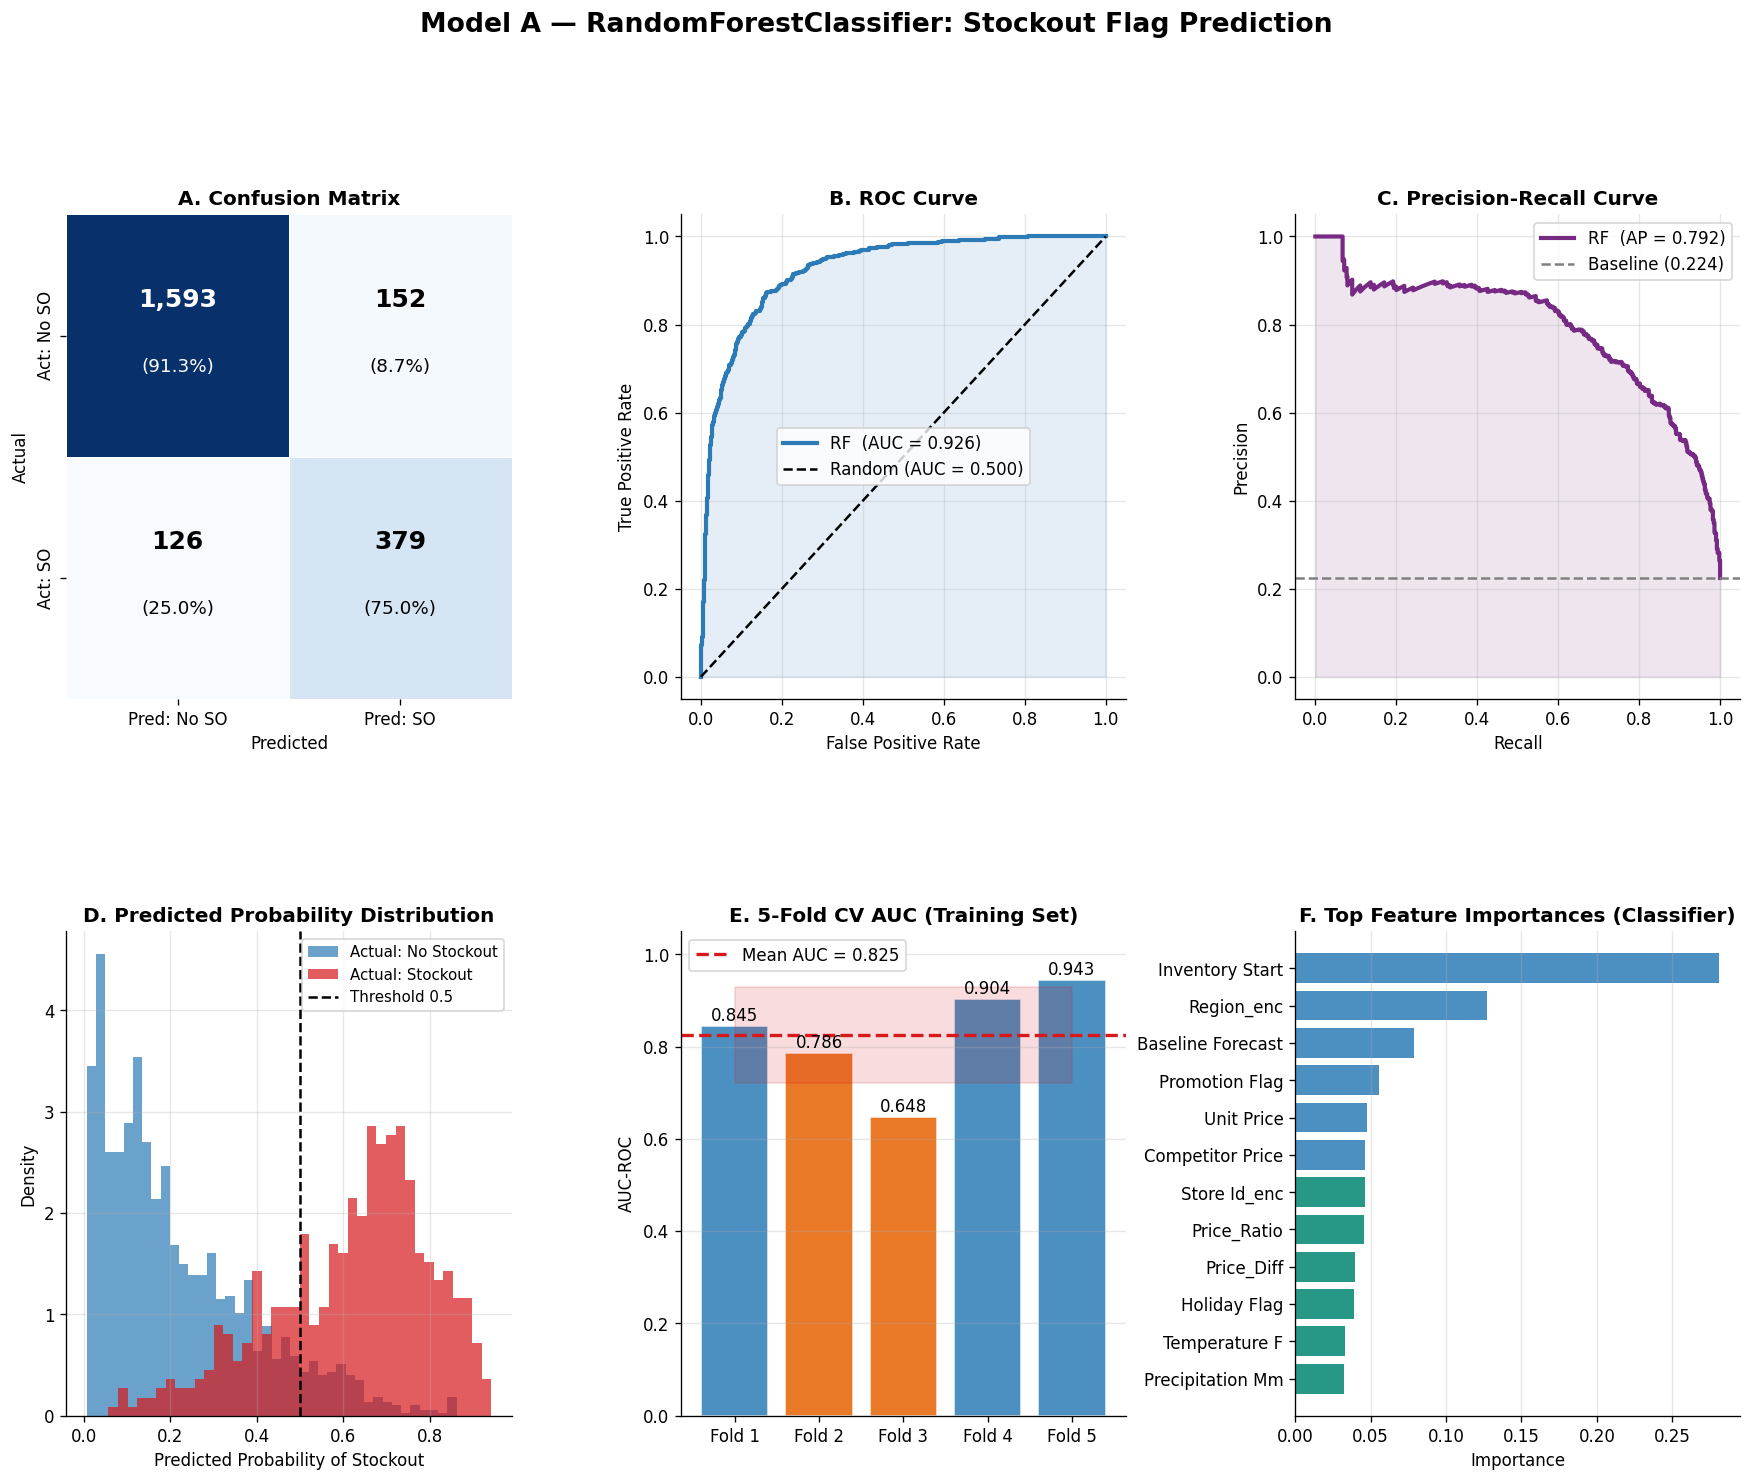

In [ ]:
# ── Classification Graphs ────────────────────────────────────────────────────
fig = plt.figure(figsize=(18, 13))
fig.suptitle("Model A — RandomForestClassifier: Stockout Flag Prediction",
             fontsize=16, fontweight="bold", y=1.01)
gs = gridspec.GridSpec(2, 3, figure=fig, hspace=0.48, wspace=0.38)

# A. Confusion Matrix
ax = fig.add_subplot(gs[0, 0])
cm_pct = cm.astype(float) / cm.sum(axis=1, keepdims=True) * 100
sns.heatmap(cm, annot=False, cmap="Blues", ax=ax,
            xticklabels=["Pred: No SO", "Pred: SO"],
            yticklabels=["Act: No SO", "Act: SO"],
            linewidths=0.5, cbar=False)
for i in range(2):
    for j in range(2):
        ax.text(j+0.5, i+0.38, f"{cm[i,j]:,}", ha="center", fontsize=15,
                fontweight="bold", color="white" if cm[i,j] > cm.max()/2 else "black")
        ax.text(j+0.5, i+0.65, f"({cm_pct[i,j]:.1f}%)", ha="center", fontsize=11,
                color="white" if cm[i,j] > cm.max()/2 else "black")
ax.set_title("A. Confusion Matrix", fontsize=12, fontweight="bold")
ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")

# B. ROC Curve
ax = fig.add_subplot(gs[0, 1])
ax.plot(fpr, tpr, color=PALETTE["blue"], lw=2.5, label=f"RF  (AUC = {auc:.3f})")
ax.plot([0, 1], [0, 1], "k--", lw=1.5, label="Random (AUC = 0.500)")
ax.fill_between(fpr, tpr, alpha=0.12, color=PALETTE["blue"])
ax.set_xlabel("False Positive Rate"); ax.set_ylabel("True Positive Rate")
ax.set_title("B. ROC Curve", fontsize=12, fontweight="bold")
ax.legend(fontsize=10); ax.grid(alpha=0.3)

# C. Precision-Recall
ax = fig.add_subplot(gs[0, 2])
baseline_pr = yc_test.mean()
ax.plot(rec, prec, color=PALETTE["purple"], lw=2.5, label=f"RF  (AP = {ap_score:.3f})")
ax.axhline(baseline_pr, color="grey", ls="--", lw=1.5, label=f"Baseline ({baseline_pr:.3f})")
ax.fill_between(rec, prec, alpha=0.12, color=PALETTE["purple"])
ax.set_xlabel("Recall"); ax.set_ylabel("Precision")
ax.set_title("C. Precision-Recall Curve", fontsize=12, fontweight="bold")
ax.legend(fontsize=10); ax.grid(alpha=0.3)

# D. Probability distribution
ax = fig.add_subplot(gs[1, 0])
prob_no = yc_pred_prob[yc_test == 0]
prob_so = yc_pred_prob[yc_test == 1]
ax.hist(prob_no, bins=40, alpha=0.7, color=PALETTE["blue"],
        label="Actual: No Stockout", density=True)
ax.hist(prob_so, bins=40, alpha=0.7, color=PALETTE["red"],
        label="Actual: Stockout", density=True)
ax.axvline(0.5, color="black", ls="--", lw=1.5, label="Threshold 0.5")
ax.set_xlabel("Predicted Probability of Stockout")
ax.set_ylabel("Density")
ax.set_title("D. Predicted Probability Distribution", fontsize=12, fontweight="bold")
ax.legend(fontsize=9); ax.grid(alpha=0.3)

# E. CV AUC
ax = fig.add_subplot(gs[1, 1])
fold_labels = [f"Fold {i+1}" for i in range(len(cv_auc))]
bar_colors = [PALETTE["blue"] if v >= cv_auc.mean() else PALETTE["orange"] for v in cv_auc]
bars = ax.bar(fold_labels, cv_auc, color=bar_colors, alpha=0.85, edgecolor="white")
ax.axhline(cv_auc.mean(), color=PALETTE["red"], ls="--", lw=2,
           label=f"Mean AUC = {cv_auc.mean():.3f}")
ax.fill_between(range(len(cv_auc)),
                cv_auc.mean() - cv_auc.std(), cv_auc.mean() + cv_auc.std(),
                alpha=0.15, color=PALETTE["red"])
for bar, val in zip(bars, cv_auc):
    ax.text(bar.get_x() + bar.get_width()/2, val + 0.003,
            f"{val:.3f}", ha="center", va="bottom", fontsize=10)
ax.set_ylim(0, 1.05); ax.set_ylabel("AUC-ROC")
ax.set_title("E. 5-Fold CV AUC (Training Set)", fontsize=12, fontweight="bold")
ax.legend(fontsize=10); ax.grid(axis="y", alpha=0.3)

# F. Feature Importances
ax = fig.add_subplot(gs[1, 2])
fi_clf = pd.Series(clf.feature_importances_, index=FEATURES_CLF).sort_values(ascending=True).tail(12)
colors = [PALETTE["blue"] if v >= fi_clf.median() else PALETTE["teal"] for v in fi_clf.values]
ax.barh(fi_clf.index, fi_clf.values, color=colors, alpha=0.85)
ax.set_xlabel("Importance")
ax.set_title("F. Top Feature Importances (Classifier)", fontsize=12, fontweight="bold")
ax.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()


---
6. Model B — RandomForestRegressor (Y2: Sales Quantity)

In [ ]:
reg = RandomForestRegressor(
    n_estimators=300,
    max_depth=15,
    min_samples_split=10,
    min_samples_leaf=5,
    max_features="sqrt",
    random_state=SEED,
    n_jobs=-1,
)
reg.fit(X_train_r, yr_train)
print("Regressor trained.")


Regressor trained.


In [ ]:
# ── Predictions & metrics ─────────────────────────────────────────────────────
yr_pred   = reg.predict(X_test_r)
residuals = yr_test.values - yr_pred

mae  = mean_absolute_error(yr_test, yr_pred)
rmse = np.sqrt(mean_squared_error(yr_test, yr_pred))
r2   = r2_score(yr_test, yr_pred)
mape = np.mean(np.abs(residuals / (yr_test.values + 1e-6))) * 100

base_mae  = mean_absolute_error(yr_test, baseline_test)
base_rmse = np.sqrt(mean_squared_error(yr_test, baseline_test))
base_r2   = r2_score(yr_test, baseline_test)

kf = KFold(n_splits=5, shuffle=False)
cv_r2 = cross_val_score(reg, X_train_r, yr_train, cv=kf, scoring="r2", n_jobs=-1)

print(f"{'Metric':<22} {'Random Forest':>15} {'Baseline':>12}  {'Improvement':>12}")
print("─" * 65)
print(f"{'MAE':<22} {mae:>15.3f} {base_mae:>12.3f}  {((base_mae-mae)/base_mae*100):>11.1f}%")
print(f"{'RMSE':<22} {rmse:>15.3f} {base_rmse:>12.3f}  {((base_rmse-rmse)/base_rmse*100):>11.1f}%")
print(f"{'R²':<22} {r2:>15.4f} {base_r2:>12.4f}")
print(f"{'MAPE':<22} {mape:>14.2f}%")
print(f"{'CV R² (5-fold)':<22} {cv_r2.mean():>13.4f}±{cv_r2.std():.4f}")


Metric                   Random Forest     Baseline   Improvement
─────────────────────────────────────────────────────────────────
MAE                             11.261       34.459         67.3%
RMSE                            19.670       56.424         65.1%
R²                              0.9413       0.5167
MAPE                            14.28%
CV R² (5-fold)                0.8682±0.1005


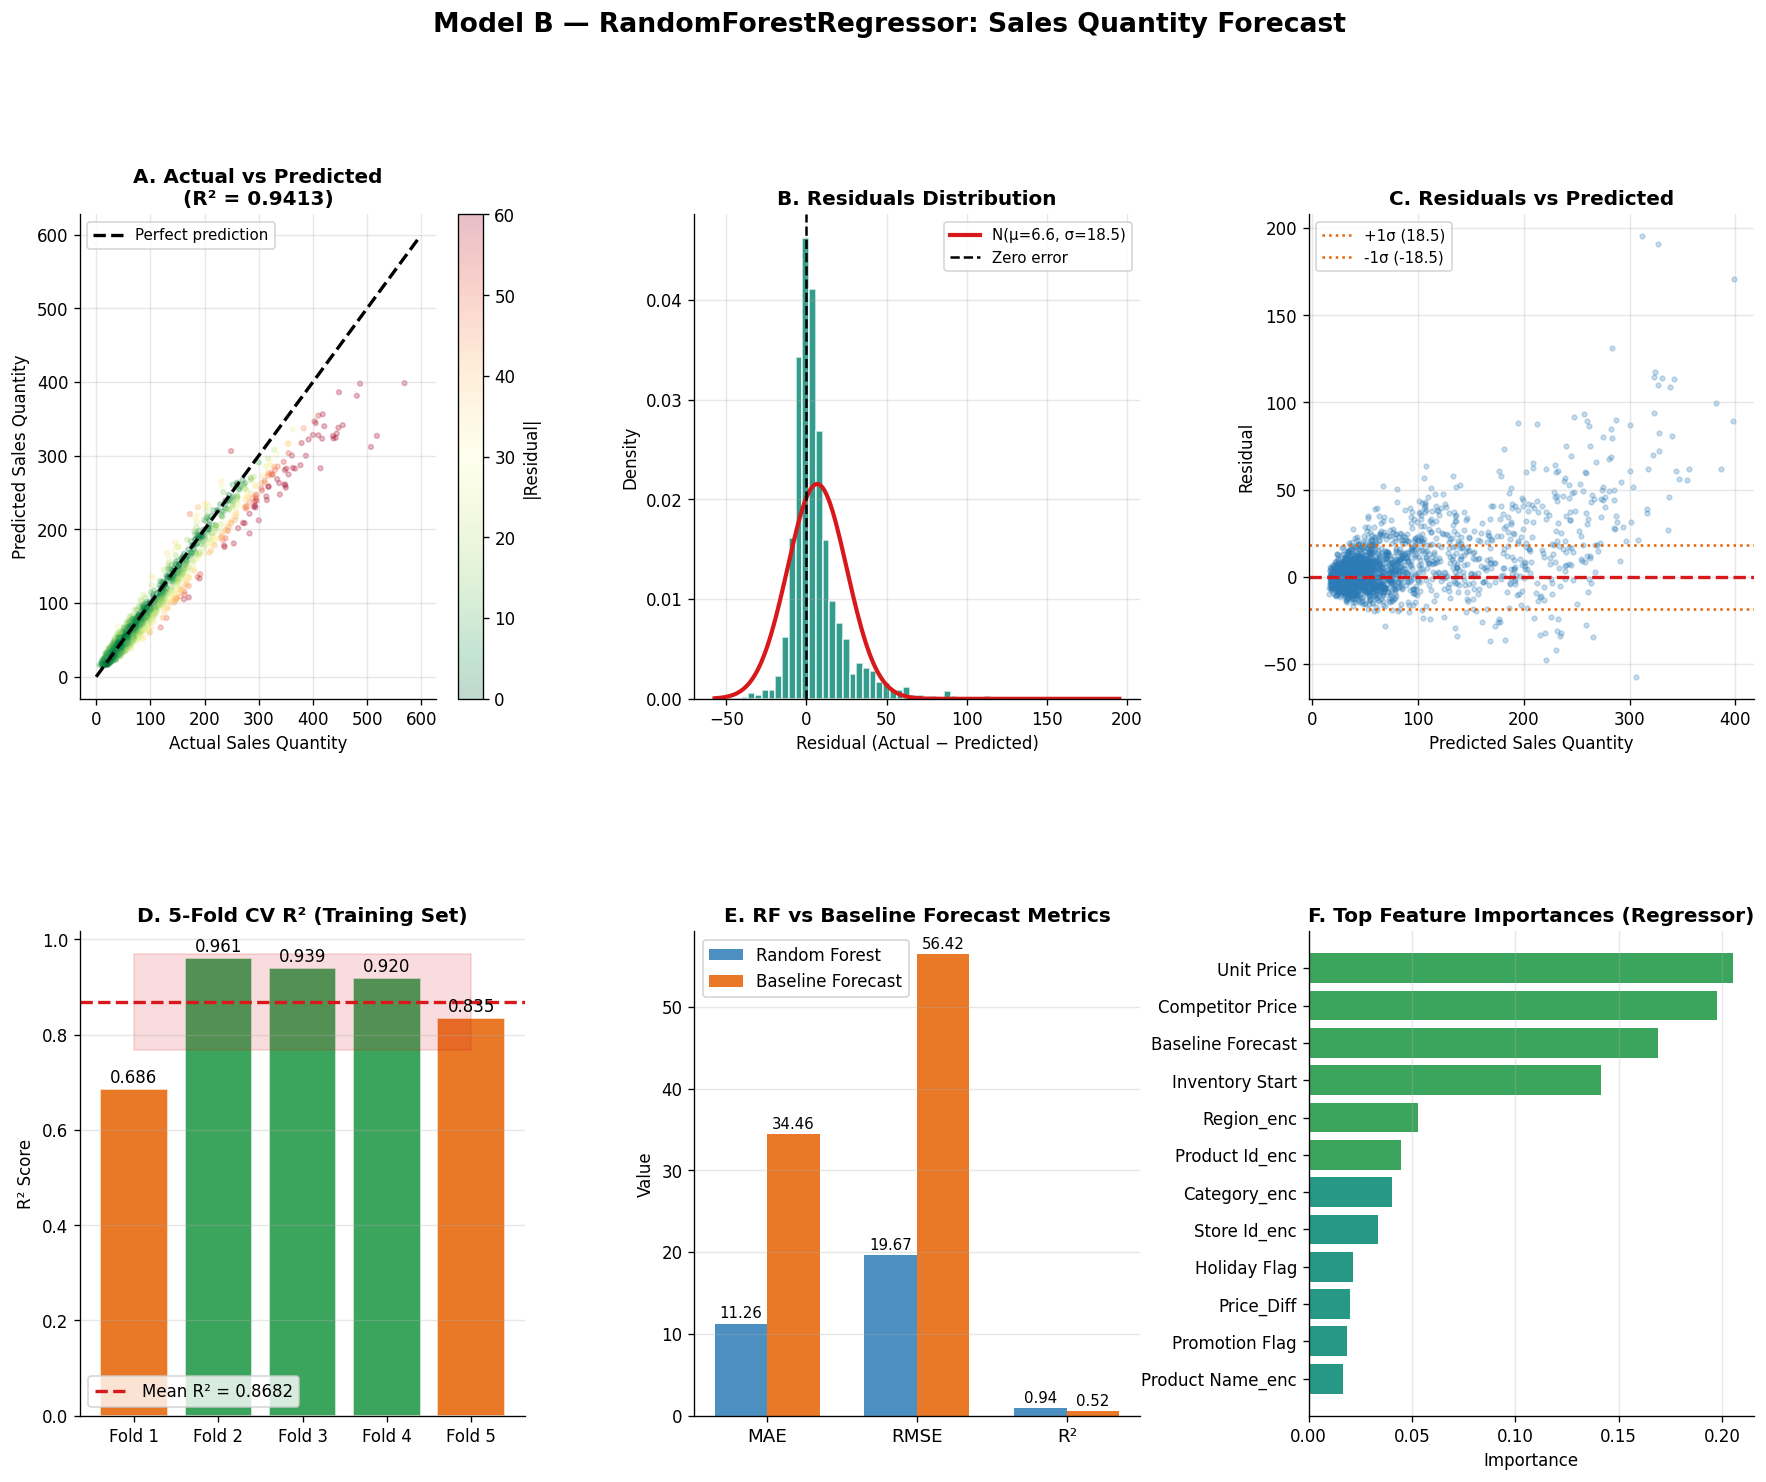

In [ ]:
# ── Regression Graphs ────────────────────────────────────────────────────────
fig = plt.figure(figsize=(18, 13))
fig.suptitle("Model B — RandomForestRegressor: Sales Quantity Forecast",
             fontsize=16, fontweight="bold", y=1.01)
gs = gridspec.GridSpec(2, 3, figure=fig, hspace=0.48, wspace=0.38)

# A. Actual vs Predicted
ax = fig.add_subplot(gs[0, 0])
sc = ax.scatter(yr_test, yr_pred, alpha=0.25, s=8,
                c=np.abs(residuals), cmap="RdYlGn_r", vmin=0, vmax=60)
plt.colorbar(sc, ax=ax, label="|Residual|")
lo, hi = 0, max(yr_test.max(), yr_pred.max()) * 1.05
ax.plot([lo, hi], [lo, hi], "k--", lw=2, label="Perfect prediction")
ax.set_xlabel("Actual Sales Quantity"); ax.set_ylabel("Predicted Sales Quantity")
ax.set_title(f"A. Actual vs Predicted\n(R² = {r2:.4f})", fontsize=12, fontweight="bold")
ax.legend(fontsize=9); ax.grid(alpha=0.3)

# B. Residuals distribution
ax = fig.add_subplot(gs[0, 1])
ax.hist(residuals, bins=60, color=PALETTE["teal"], alpha=0.8, edgecolor="white", density=True)
mu, sigma = residuals.mean(), residuals.std()
x_norm = np.linspace(residuals.min(), residuals.max(), 200)
ax.plot(x_norm, norm.pdf(x_norm, mu, sigma), color=PALETTE["red"], lw=2.5,
        label=f"N(μ={mu:.1f}, σ={sigma:.1f})")
ax.axvline(0, color="black", ls="--", lw=1.5, label="Zero error")
ax.set_xlabel("Residual (Actual − Predicted)"); ax.set_ylabel("Density")
ax.set_title("B. Residuals Distribution", fontsize=12, fontweight="bold")
ax.legend(fontsize=9); ax.grid(alpha=0.3)

# C. Residuals vs Predicted
ax = fig.add_subplot(gs[0, 2])
ax.scatter(yr_pred, residuals, alpha=0.25, s=8, color=PALETTE["blue"])
ax.axhline(0, color=PALETTE["red"], ls="--", lw=2)
ax.axhline(sigma, color=PALETTE["orange"], ls=":", lw=1.5, label=f"+1σ ({sigma:.1f})")
ax.axhline(-sigma, color=PALETTE["orange"], ls=":", lw=1.5, label=f"-1σ ({-sigma:.1f})")
ax.set_xlabel("Predicted Sales Quantity"); ax.set_ylabel("Residual")
ax.set_title("C. Residuals vs Predicted", fontsize=12, fontweight="bold")
ax.legend(fontsize=9); ax.grid(alpha=0.3)

# D. CV R²
ax = fig.add_subplot(gs[1, 0])
fold_labels = [f"Fold {i+1}" for i in range(len(cv_r2))]
bar_colors = [PALETTE["green"] if v >= cv_r2.mean() else PALETTE["orange"] for v in cv_r2]
bars = ax.bar(fold_labels, cv_r2, color=bar_colors, alpha=0.85, edgecolor="white")
ax.axhline(cv_r2.mean(), color=PALETTE["red"], ls="--", lw=2,
           label=f"Mean R² = {cv_r2.mean():.4f}")
ax.fill_between(range(len(cv_r2)),
                cv_r2.mean() - cv_r2.std(), cv_r2.mean() + cv_r2.std(),
                alpha=0.15, color=PALETTE["red"])
for bar, val in zip(bars, cv_r2):
    ax.text(bar.get_x() + bar.get_width()/2, val + 0.005,
            f"{val:.3f}", ha="center", va="bottom", fontsize=10)
ax.set_ylabel("R² Score")
ax.set_title("D. 5-Fold CV R² (Training Set)", fontsize=12, fontweight="bold")
ax.legend(fontsize=10); ax.grid(axis="y", alpha=0.3)

# E. RF vs Baseline
ax = fig.add_subplot(gs[1, 1])
metrics = ["MAE", "RMSE", "R²"]
rf_vals   = [mae, rmse, r2]
base_vals = [base_mae, base_rmse, base_r2]
x = np.arange(len(metrics)); w = 0.35
bars1 = ax.bar(x - w/2, rf_vals,   w, label="Random Forest",    color=PALETTE["blue"],   alpha=0.85)
bars2 = ax.bar(x + w/2, base_vals, w, label="Baseline Forecast", color=PALETTE["orange"], alpha=0.85)
ax.set_xticks(x); ax.set_xticklabels(metrics, fontsize=11)
ax.set_ylabel("Value")
ax.set_title("E. RF vs Baseline Forecast Metrics", fontsize=12, fontweight="bold")
ax.legend(fontsize=10); ax.grid(axis="y", alpha=0.3)
for bar in list(bars1) + list(bars2):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3,
            f"{bar.get_height():.2f}", ha="center", va="bottom", fontsize=9)

# F. Feature Importances
ax = fig.add_subplot(gs[1, 2])
fi_reg = pd.Series(reg.feature_importances_, index=FEATURES_REG).sort_values(ascending=True).tail(12)
colors = [PALETTE["green"] if v >= fi_reg.median() else PALETTE["teal"] for v in fi_reg.values]
ax.barh(fi_reg.index, fi_reg.values, color=colors, alpha=0.85)
ax.set_xlabel("Importance")
ax.set_title("F. Top Feature Importances (Regressor)", fontsize=12, fontweight="bold")
ax.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()


---
7. Time-Series: Actual vs Predicted Sales (Sample Product)

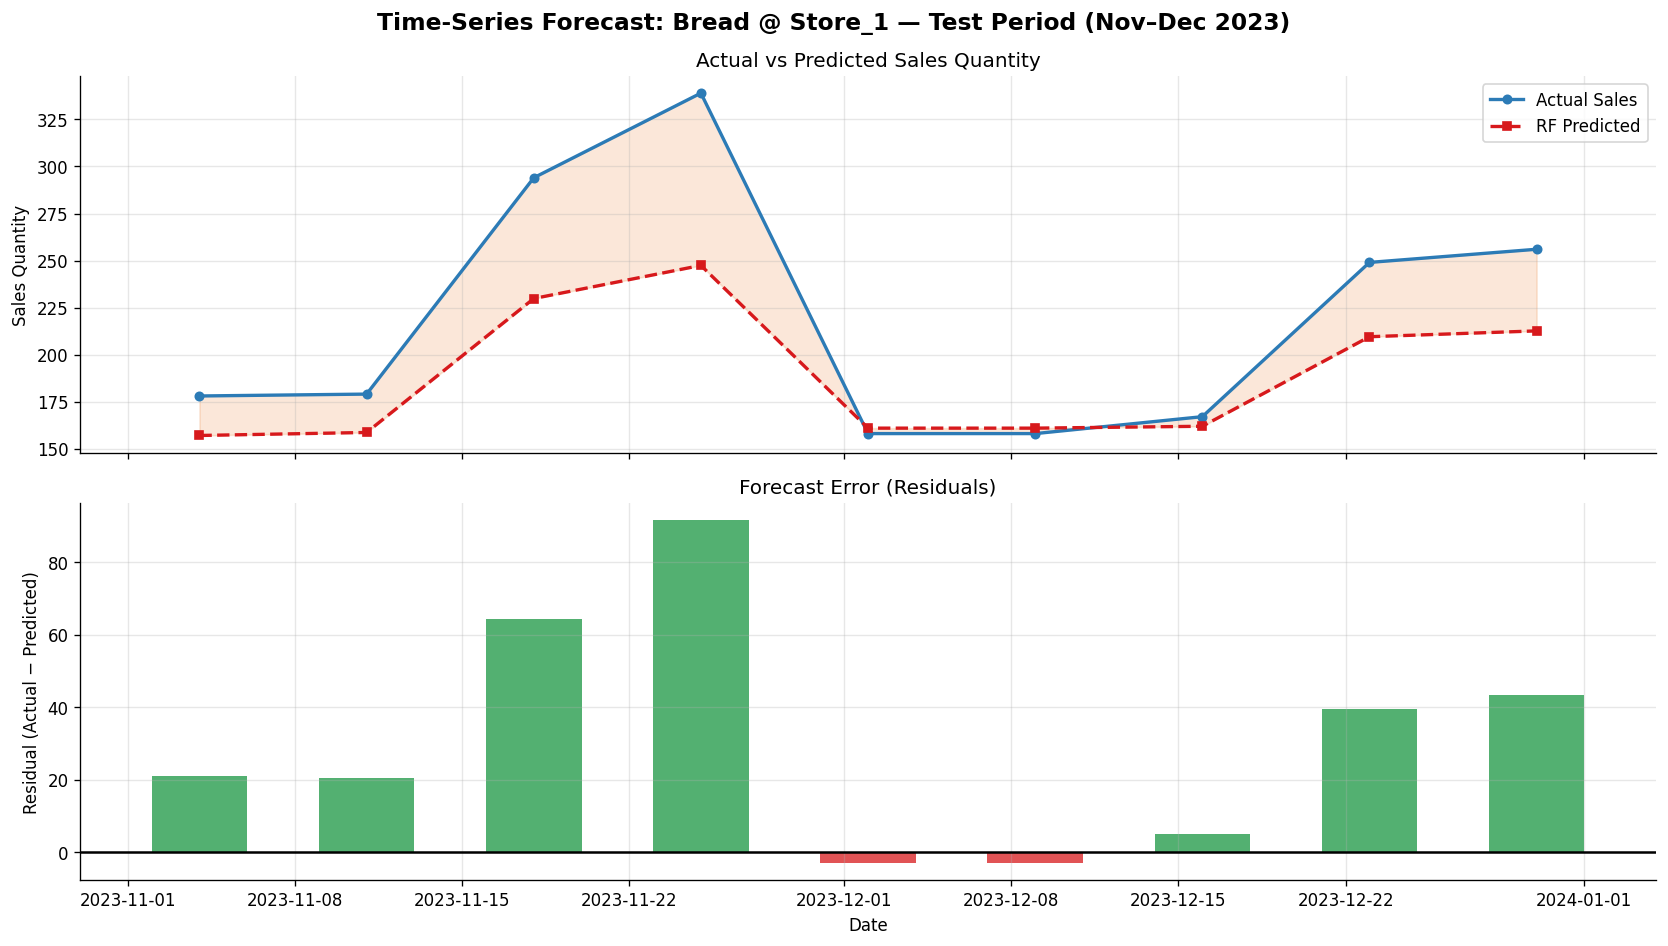

In [ ]:
sample = test_df[["Date", "Product Name", "Store Id"]].copy()
sample["Actual"]    = yr_test.values
sample["Predicted"] = yr_pred.round(1)
sample["Residual"]  = residuals.round(1)

top_prod  = test_df["Product Name"].mode()[0]
top_store = test_df["Store Id"].mode()[0]
mask = (test_df["Product Name"] == top_prod) & (test_df["Store Id"] == top_store)
ts = sample[mask].sort_values("Date")

fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)
fig.suptitle(f"Time-Series Forecast: {top_prod} @ {top_store} — Test Period (Nov–Dec 2023)",
             fontsize=14, fontweight="bold")

ax = axes[0]
ax.plot(ts["Date"], ts["Actual"],    color=PALETTE["blue"], lw=2, marker="o", ms=5, label="Actual Sales")
ax.plot(ts["Date"], ts["Predicted"], color=PALETTE["red"],  lw=2, ls="--", marker="s", ms=5, label="RF Predicted")
ax.fill_between(ts["Date"], ts["Actual"], ts["Predicted"], alpha=0.15, color=PALETTE["orange"])
ax.set_ylabel("Sales Quantity"); ax.legend(fontsize=10); ax.grid(alpha=0.3)
ax.set_title("Actual vs Predicted Sales Quantity", fontsize=12)

ax = axes[1]
colors_r = [PALETTE["red"] if r < 0 else PALETTE["green"] for r in ts["Residual"]]
ax.bar(ts["Date"], ts["Residual"], color=colors_r, alpha=0.75, width=4)
ax.axhline(0, color="black", lw=1.5)
ax.set_ylabel("Residual (Actual − Predicted)"); ax.grid(alpha=0.3)
ax.set_title("Forecast Error (Residuals)", fontsize=12); ax.set_xlabel("Date")

plt.tight_layout()
plt.show()


---
8. Export Results & Final Summary

In [ ]:
test_idx = X_test_c.index
out_df = df.loc[test_idx, ["Date","Product Id","Product Name",
                             "Category","Store Id","Region"]].copy()
out_df["Actual_Stockout"]         = yc_test.values
out_df["RF_Predicted_Stockout"]   = yc_pred
out_df["RF_Stockout_Probability"] = yc_pred_prob.round(4)
out_df["Actual_Sales_Qty"]        = yr_test.values
out_df["RF_Predicted_Sales_Qty"]  = yr_pred.round(1)
out_df["RF_Residual"]             = residuals.round(1)
out_df.to_csv("rf_predictions_output.csv", index=False)

print(f"Saved rf_predictions_output.csv  ({len(out_df):,} rows)")
print()
print("═" * 62)
print("  FINAL SUMMARY  (leakage-free, realistic results)")
print("═" * 62)
print(f"  MODEL A — RandomForestClassifier (Y1: Stockout Flag)")
print(f"    AUC-ROC        : {auc:.4f}")
print(f"    Avg Precision  : {ap_score:.4f}")
print(f"    CV AUC (5-Fold): {cv_auc.mean():.4f} ± {cv_auc.std():.4f}")
print()
print(f"  MODEL B — RandomForestRegressor (Y2: Sales Qty)")
print(f"    MAE            : {mae:.3f}")
print(f"    RMSE           : {rmse:.3f}")
print(f"    R²             : {r2:.4f}")
print(f"    MAPE           : {mape:.2f}%")
print(f"    CV R² (5-Fold) : {cv_r2.mean():.4f} ± {cv_r2.std():.4f}")
print()
print(f"  BASELINE COMPARISON")
print(f"    Baseline MAE   : {base_mae:.3f}  → RF is {((base_mae-mae)/base_mae*100):.1f}% better")
print(f"    Baseline RMSE  : {base_rmse:.3f}  → RF is {((base_rmse-rmse)/base_rmse*100):.1f}% better")
print(f"    Baseline R²    : {base_r2:.4f}")
print("═" * 62)

out_df.head(10)


Saved rf_predictions_output.csv  (2,250 rows)

══════════════════════════════════════════════════════════════
  FINAL SUMMARY  (leakage-free, realistic results)
══════════════════════════════════════════════════════════════
  MODEL A — RandomForestClassifier (Y1: Stockout Flag)
    AUC-ROC        : 0.9260
    Avg Precision  : 0.7924
    CV AUC (5-Fold): 0.8254 ± 0.1035

  MODEL B — RandomForestRegressor (Y2: Sales Qty)
    MAE            : 11.261
    RMSE           : 19.670
    R²             : 0.9413
    MAPE           : 14.28%
    CV R² (5-Fold) : 0.8682 ± 0.1005

  BASELINE COMPARISON
    Baseline MAE   : 34.459  → RF is 67.3% better
    Baseline RMSE  : 56.424  → RF is 65.1% better
    Baseline R²    : 0.5167
══════════════════════════════════════════════════════════════


,Date,Product Id,Product Name,Category,Store Id,Region,Actual_Stockout,RF_Predicted_Stockout,RF_Stockout_Probability,Actual_Sales_Qty,RF_Predicted_Sales_Qty,RF_Residual
96,2023-11-04,P001,Laptop,Electronics,Store_1,North,0,0,0.1252,34,28.9,5.1
97,2023-11-11,P001,Laptop,Electronics,Store_1,North,1,0,0.4889,25,30.9,-5.9
98,2023-11-18,P001,Laptop,Electronics,Store_1,North,0,0,0.4180,55,43.1,11.9
99,2023-11-25,P001,Laptop,Electronics,Store_1,North,0,0,0.2660,46,47.4,-1.4
100,2023-12-02,P001,Laptop,Electronics,Store_1,North,0,0,0.1932,45,37.1,7.9
101,2023-12-09,P001,Laptop,Electronics,Store_1,North,1,0,0.4716,32,31.8,0.2
102,2023-12-16,P001,Laptop,Electronics,Store_1,North,0,0,0.2248,50,37.4,12.6
103,2023-12-23,P001,Laptop,Electronics,Store_1,North,0,0,0.2765,59,43.7,15.3
104,2023-12-30,P001,Laptop,Electronics,Store_1,North,0,0,0.3289,50,46.9,3.1
201,2023-11-04,P002,Headphones,Electronics,Store_1,North,0,0,0.1018,37,34.8,2.2
